# U00 — Soft self-history brute-force calibration

This starts the **U-series**. C05 is paused until the U intervention is frozen.

U00 studies **only the generation-side temporal intervention**: no Unique controller, no NFZ suffix, no Ghostbuster scoring, and no detector-aware selection. The only automatic outcome is the completed-text context-utility trace \(U\); prose quality/lobotomization is reviewed manually and blindly.

For the same prompt \(P\), define

\[
p_F(x_t)=p(x_t\mid P,x_{<t}),\qquad
p_K(x_t)=p(x_t\mid P,x_{t-K:t-1}).
\]

U00 uses the arithmetic probability mixture

\[
q_{\lambda,K}(x_t)=(1-\lambda)p_F(x_t)+\lambda p_K(x_t).
\]

Thus \(\lambda=0\) is ordinary full-history generation and \(\lambda=1\) is the old hard cap.

### Coarse pilot

Use six deterministic sources from the frozen 54-source cohort, one each from `abstracts, books, news, recipes, reddit, wiki`, and generate:

\[
\{\text{Full},K32_{\lambda=.25,.50,.75,1},K64_{\lambda=.25,.50,.75,1}\}.
\]

That is \(6\times9=54\) generations.

Primary readout: \(U(128)\) on a 256-scorer-token calibration prefix. Canonical paper \(U(256)\) on 384 tokens is reported whenever available. Policy choice must not use Ghostbuster.


In [1]:
from pathlib import Path
import gc,math,hashlib,string
import numpy as np,pandas as pd,torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from transformers import AutoTokenizer,AutoModelForCausalLM
from IPython.display import display

ROOT=Path.cwd().resolve()
if ROOT.name=="experiments":ROOT=ROOT.parent
if not (ROOT/"results").exists() and (ROOT.parent/"results").exists():ROOT=ROOT.parent
assert (ROOT/"results").exists(),ROOT
TCR_ROOT=ROOT.parent
OUT=ROOT/"results/causal/U00_soft_history_bruteforce";OUT.mkdir(parents=True,exist_ok=True)
FIG=ROOT/"figures";FIG.mkdir(exist_ok=True)

SEED=20260915
GENERATOR="Qwen/Qwen2.5-1.5B-Instruct"
SCORER="Qwen/Qwen3-0.6B-Base"
MAX_NEW_TOKENS=480
PILOT_DOMAINS=["abstracts","books","news","recipes","reddit","wiki"]
N_BOOT=5000
POLICIES=[
 {"policy":"FULL","K":None,"lambda":0.0},
 {"policy":"S32_025","K":32,"lambda":0.25},
 {"policy":"S32_050","K":32,"lambda":0.50},
 {"policy":"S32_075","K":32,"lambda":0.75},
 {"policy":"HARD32","K":32,"lambda":1.0},
 {"policy":"S64_025","K":64,"lambda":0.25},
 {"policy":"S64_050","K":64,"lambda":0.50},
 {"policy":"S64_075","K":64,"lambda":0.75},
 {"policy":"HARD64","K":64,"lambda":1.0},
]
policy_df=pd.DataFrame(POLICIES)
display(policy_df)
print("ROOT:",ROOT,"\nOUT:",OUT)


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,policy,K,lambda
0,FULL,NaN,0.00
1,S32_025,32.0,0.25
2,S32_050,32.0,0.50
3,S32_075,32.0,0.75
4,HARD32,32.0,1.00
5,S64_025,64.0,0.25
6,S64_050,64.0,0.50
7,S64_075,64.0,0.75
8,HARD64,64.0,1.00


ROOT: .. 
OUT: ../results/causal/U00_soft_history_bruteforce


In [2]:
# Recover the canonical fixed-54 membership.
STEP10_ROOT=ROOT/"results/causal/C04c_CARDINAL_controlled_insertion"
canonical=STEP10_ROOT/"16d25f12a76b"/"texts_after_CARDINAL_step10.csv"
if not canonical.exists():
    hits=[]
    for p in STEP10_ROOT.glob("*"):
        s=p/"stage_summary.csv";t=p/"texts_after_CARDINAL_step10.csv"
        if s.exists() and t.exists():
            q=pd.read_csv(s)
            if np.isclose(float(q.iloc[-1].AUROC),.6713260906186861,atol=1e-9):hits.append(t)
    assert len(hits)==1,hits
    canonical=hits[0]
fixed54=pd.read_csv(canonical,keep_default_na=False)[["case_id","source_id","domain"]].copy()
assert len(fixed54)==54 and fixed54.source_id.nunique()==54
display(fixed54.domain.value_counts())


domain
news         12
abstracts    10
recipes       9
wiki          9
books         7
reddit        6
reviews       1
Name: count, dtype: int64

## Recover exact RAID prompts

The intervention regenerates from the original RAID task, not from NFZ text. We recover the canonical `prompt` field by `source_id` from local parquet files and require one unique prompt per source.


In [6]:
# Recover canonical RAID instruction prompts for the broader fixed54 cohort.
PROMPT_CACHE=OUT/"fixed54_prompts.parquet"

def raw_raid_id(x):
    x=str(x)
    return x.split("ai__raid:",1)[1] if x.startswith("ai__raid:") else x

if PROMPT_CACHE.exists():
    prompts54=pd.read_parquet(PROMPT_CACHE)
    print("Loaded:",PROMPT_CACHE)
else:
    target=fixed54.copy()
    target["raw_id"]=target.source_id.map(raw_raid_id)
    wanted=set(target.raw_id)

    RAID_CSV=Path.home()/".cache"/"raid"/"train.csv"
    assert RAID_CSV.exists(),RAID_CSV

    header=pd.read_csv(RAID_CSV,nrows=0).columns.tolist()
    print("RAID columns:",header)

    idcol="source_id" if "source_id" in header else "id"
    needed=[idcol,"prompt","model","attack"]
    for c in ["decoding","repetition_penalty","domain","title"]:
        if c in header: needed.append(c)

    pieces=[]
    for z in tqdm(
        pd.read_csv(RAID_CSV,usecols=needed,chunksize=100_000),
        desc="scan full RAID"
    ):
        z["raw_id"]=z[idcol].astype(str).map(raw_raid_id)
        z=z[z.raw_id.isin(wanted)].copy()
        if len(z): pieces.append(z)

    assert pieces,"No fixed54 rows found in full RAID cache."
    raid=pd.concat(pieces,ignore_index=True)

    # Same clean generation condition used in the earlier U work.
    raid=raid[raid.attack.astype(str).str.lower().eq("none")].copy()

    if "decoding" in raid.columns:
        raid=raid[raid.decoding.astype(str).str.lower().eq("greedy")].copy()

    if "repetition_penalty" in raid.columns:
        raid=raid[
            raid.repetition_penalty.astype(str).str.lower().eq("no")
        ].copy()

    # RAID chat/instruction generators use the task-instruction prompt formulation.
    INSTRUCTION_MODELS={"chatgpt","gpt4","llama-chat"}
    inst=raid[
        raid.model.astype(str).str.lower().isin(INSTRUCTION_MODELS)
        & raid.prompt.notna()
    ].copy()

    inst["prompt"]=inst.prompt.astype(str).str.strip()

    print("Instruction-model rows:",len(inst))
    print("Fixed54 represented:",inst.raw_id.nunique(),"/",len(wanted))
    display(inst.model.value_counts())

    prompt_sets=inst.groupby("raw_id").prompt.agg(
        lambda s:list(pd.unique(s))
    )

    bad=prompt_sets[prompt_sets.map(len)!=1]
    if len(bad):
        print("Instruction-prompt disagreements:")
        display(bad)
        raise RuntimeError(
            f"{len(bad)} fixed sources have conflicting instruction prompts."
        )

    missing=wanted-set(prompt_sets.index)
    assert not missing,(
        f"Missing canonical instruction prompts for {len(missing)}/54:\n"
        +"\n".join(sorted(missing))
    )

    prompt_map={sid:v[0] for sid,v in prompt_sets.items()}

    prompts54=target.copy()
    prompts54["prompt"]=prompts54.raw_id.map(prompt_map)

    assert prompts54.prompt.notna().all()
    assert prompts54.prompt.str.len().gt(0).all()

    prompts54=prompts54.drop(columns="raw_id")
    prompts54.to_parquet(PROMPT_CACHE,index=False)
    print("Saved:",PROMPT_CACHE)

print("prompts:",len(prompts54))
display(
    prompts54[
        ["case_id","source_id","domain","prompt"]
    ].head(10)
)

RAID columns: ['id', 'adv_source_id', 'source_id', 'model', 'decoding', 'repetition_penalty', 'attack', 'domain', 'title', 'prompt', 'generation']


scan full RAID: 57it [00:39,  1.45it/s]

Instruction-model rows: 162
Fixed54 represented: 54 / 54


model
llama-chat    54
chatgpt       54
gpt4          54
Name: count, dtype: int64

Saved: ../results/causal/U00_soft_history_bruteforce/fixed54_prompts.parquet
prompts: 54


,case_id,source_id,domain,prompt
0,gate_0001,ai__raid:af383c6d-11c9-4169-a2fa-58280f83ca96,abstracts,Write the abstract for the academic paper titl...
1,gate_0003,ai__raid:2abdd1df-30c9-4db4-bc75-08ae57b9ec93,news,"Write the body of a BBC news article titled ""G..."
2,gate_0004,ai__raid:f5f280b6-e8c1-4f10-9d16-0e6297e8c730,recipes,"Write a recipe for ""Vegetable Turkey Soup With..."
3,gate_0005,ai__raid:7bd2da2a-4f21-4b84-91a7-2cb37fd80071,reddit,"Write just the body of a Reddit post titled ""H..."
4,gate_0007,ai__raid:ae32af9e-d8dc-415d-bb9f-051981e11dd4,wiki,"Write the body of a Wikipedia article titled ""..."
5,gate_0015,ai__raid:cfb5728e-c896-4ed5-8173-f39be5ff5f97,abstracts,Write the abstract for the academic paper titl...
6,gate_0016,ai__raid:296752cd-3b82-479f-b5a9-0bb1001ba706,books,Write the body of a plot summary for a novel t...
7,gate_0017,ai__raid:b4b807b1-fbfa-43d8-9fc3-61bd36b078ef,news,"Write the body of a BBC news article titled ""J..."
8,gate_0018,ai__raid:6caeff0b-6fa7-4fea-9a48-342fe2d6b83b,recipes,"Write a recipe for ""Z Bar Like Butta Zeppoles""."
9,gate_0019,ai__raid:dc315335-0314-49c5-96b1-3211dc072983,reddit,"Write just the body of a Reddit post titled ""M..."


In [7]:
# Freeze one deterministic random source from each major genre.
PILOT_PATH=OUT/"pilot_sources.csv"
if PILOT_PATH.exists():
    pilot=pd.read_csv(PILOT_PATH,keep_default_na=False)
else:
    rng=np.random.default_rng(SEED);rows=[]
    for domain in PILOT_DOMAINS:
        g=prompts54[prompts54.domain.eq(domain)].sort_values("source_id").reset_index(drop=True)
        assert len(g),domain
        rows.append(g.iloc[int(rng.integers(0,len(g)))])
    pilot=pd.DataFrame(rows).reset_index(drop=True)
    pilot.to_csv(PILOT_PATH,index=False)
assert len(pilot)==6 and pilot.source_id.nunique()==6
display(pilot[["case_id","source_id","domain"]])


,case_id,source_id,domain
0,gate_0001,ai__raid:af383c6d-11c9-4169-a2fa-58280f83ca96,abstracts
1,gate_0023,ai__raid:7b6ca4a8-9f9f-4ede-a9ce-4d6ca52ac525,books
2,gate_0030,ai__raid:fcc95fec-43c3-4885-86f5-8e310a8d552f,news
3,gate_0049,ai__raid:a77e8e92-8af5-4e1d-ab67-65bf52a8d5d7,recipes
4,gate_0026,ai__raid:603b6d03-c745-4378-a2db-5b0705bddd34,reddit
5,gate_0086,ai__raid:7ced28f5-df4d-40ba-a6f1-e7fa8fbb9640,wiki


## Generate the 9 history policies

The full branch uses a normal growing KV cache. The capped branch is recomputed at every step from `[full prompt ; last K generated tokens]`, matching the old effective-history semantics. For a soft policy both branches condition on the same generated continuation.

`first_override_step` is the first token at which the mixture chooses something different from the full-history branch on that same prefix; it is only a diagnostic.


In [10]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype=torch.float16 if device.type=="cuda" else torch.float32
gtok=AutoTokenizer.from_pretrained(GENERATOR,use_fast=True)
gmodel=AutoModelForCausalLM.from_pretrained(GENERATOR,dtype=dtype,low_cpu_mem_usage=True).to(device).eval()

def make_prompt_ids(prompt):
    messages=[{"role":"user","content":str(prompt)}]
    text=gtok.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )
    return gtok(
        text,
        return_tensors="pt",
        add_special_tokens=False
    )["input_ids"].to(device)
    
eos=gmodel.generation_config.eos_token_id
if eos is None:eos=gtok.eos_token_id
EOS=set(eos if isinstance(eos,(list,tuple)) else [eos])

@torch.inference_mode()
def generate_full(prompt):
    p=make_prompt_ids(prompt);out=gmodel(input_ids=p,use_cache=True)
    logits=out.logits[:,-1,:].float();past=out.past_key_values;gen=[]
    for _ in range(MAX_NEW_TOKENS):
        nxt=int(logits.argmax(-1).item())
        if nxt in EOS:return gen,"eos"
        gen.append(nxt)
        out=gmodel(input_ids=torch.tensor([[nxt]],device=device),past_key_values=past,use_cache=True)
        logits=out.logits[:,-1,:].float();past=out.past_key_values
    return gen,"max_tokens"

@torch.inference_mode()
def generate_hard(prompt,K):
    p=make_prompt_ids(prompt)[0].tolist();gen=[]
    for _ in range(MAX_NEW_TOKENS):
        ids=torch.tensor([p+gen[-K:]],device=device)
        logits=gmodel(input_ids=ids,use_cache=False).logits[:,-1,:].float()
        nxt=int(logits.argmax(-1).item())
        if nxt in EOS:return gen,"eos"
        gen.append(nxt)
    return gen,"max_tokens"

@torch.inference_mode()
def generate_soft(prompt,K,lam):
    p0=make_prompt_ids(prompt);p=p0[0].tolist()
    out=gmodel(input_ids=p0,use_cache=True)
    full_logits=out.logits[:,-1,:].float();past=out.past_key_values
    gen=[];first=None;overrides=0;la=math.log1p(-lam);lb=math.log(lam)
    for step in range(MAX_NEW_TOKENS):
        cap=torch.tensor([p+gen[-K:]],device=device)
        cap_logits=gmodel(input_ids=cap,use_cache=False).logits[:,-1,:].float()
        full_choice=int(full_logits.argmax(-1).item())
        lq=torch.logaddexp(F.log_softmax(full_logits,-1)+la,F.log_softmax(cap_logits,-1)+lb)
        nxt=int(lq.argmax(-1).item())
        if nxt!=full_choice:
            overrides+=1
            if first is None:first=step
        if nxt in EOS:return gen,"eos",first,overrides/max(1,step+1)
        gen.append(nxt)
        out=gmodel(input_ids=torch.tensor([[nxt]],device=device),past_key_values=past,use_cache=True)
        full_logits=out.logits[:,-1,:].float();past=out.past_key_values
    return gen,"max_tokens",first,overrides/MAX_NEW_TOKENS

print("generator ready:",GENERATOR,device,dtype)



Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 338/338 [00:00<00:00, 1340.11it/s]


generator ready: Qwen/Qwen2.5-1.5B-Instruct cuda torch.float16


In [11]:
# Run/resume all 54 generations; checkpoint after every document-policy pair.
GEN_PATH=OUT/"generations.parquet"
generations=pd.read_parquet(GEN_PATH) if GEN_PATH.exists() else pd.DataFrame()
done=set(zip(generations.source_id.astype(str),generations.policy.astype(str))) if len(generations) else set()
rows=generations.to_dict("records") if len(generations) else []
pbar=tqdm(total=len(pilot)*len(POLICIES),initial=len(done),desc="U00 generations")
for src in pilot.itertuples(index=False):
    for pol in POLICIES:
        key=(str(src.source_id),pol["policy"])
        if key in done:continue
        if pol["policy"]=="FULL":
            ids,stop=generate_full(src.prompt);first=np.nan;frac=0.
        elif pol["lambda"]==1.:
            ids,stop=generate_hard(src.prompt,int(pol["K"]));first=np.nan;frac=np.nan
        else:
            ids,stop,first,frac=generate_soft(src.prompt,int(pol["K"]),float(pol["lambda"]))
        text=gtok.decode(ids,skip_special_tokens=True)
        rows.append({"case_id":src.case_id,"source_id":str(src.source_id),"domain":src.domain,
                     "policy":pol["policy"],"K":pol["K"],"lambda":pol["lambda"],
                     "generated_text":text,"generator_tokens":len(ids),"stop_reason":stop,
                     "first_override_step":first,"override_fraction":frac,
                     "text_sha":hashlib.sha256(text.encode()).hexdigest()})
        generations=pd.DataFrame(rows);generations.to_parquet(GEN_PATH,index=False);pbar.update(1)
pbar.close()
assert len(generations)==54,len(generations)
display(generations.groupby("policy").agg(n=("source_id","size"),mean_tokens=("generator_tokens","mean"),
                                          eos_rate=("stop_reason",lambda x:(x=="eos").mean())).reindex(policy_df.policy))



U00 generations:   0%|                                                                                           | 0/54 [02:42<?, ?it/s]

U00 generations:   9%|███████▋                                                                           | 5/54 [00:58<11:12, 13.73s/it][W915 02:55:04.986657541 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 27262976 bytes (free: 47775744, total: 8186822656).

U00 generations:  26%|█████████████████████▎                                                            | 14/54 [02:36<09:33, 14.33s/it][W915 02:56:43.827963736 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 35651584 bytes (free: 60358656, total: 8186822656).

U00 generations: 100%|██████████████████████████████████████████████████████████████████████████████████| 54/54 [11:50<00:00, 13.16s/it]


,n,mean_tokens,eos_rate
policy,,,
FULL,6,284.500000,0.833333
S32_025,6,322.333333,0.500000
S32_050,6,334.666667,0.500000
S32_075,6,402.000000,0.166667
HARD32,6,365.833333,0.333333
S64_025,6,306.166667,0.666667
S64_050,6,290.333333,0.833333
S64_075,6,305.333333,0.666667
HARD64,6,251.166667,0.833333


In [12]:
# Free generator before loading independent Qwen3 U scorer.
del gmodel
gc.collect()
if torch.cuda.is_available():torch.cuda.empty_cache()


## U measurement

Two protocols are kept separate.

**Calibration `p256`:** first 256 scorer tokens, 8 targets from 128–255, measuring \(L_8,L_{32},L_{128}\) and \(U(32),U(128)\).

**Canonical `p384`:** first 384 scorer tokens, 8 targets from 256–383, measuring the paper's \(U(32),U(128),U(256)\).

Short outputs remain in the generation table and simply become ineligible for the relevant scorer protocol.


In [13]:
stok=AutoTokenizer.from_pretrained(SCORER,use_fast=True)
smodel=AutoModelForCausalLM.from_pretrained(SCORER,dtype=dtype,low_cpu_mem_usage=True).to(device).eval()

@torch.inference_mode()
def score_protocol(text,prefix_len,contexts):
    allids=stok(str(text),add_special_tokens=False)["input_ids"]
    if len(allids)<prefix_len:return {"eligible":False,"scorer_tokens":len(allids)}
    ids=allids[:prefix_len];pos=np.unique(np.linspace(max(contexts),prefix_len-1,8,dtype=int));loss={}
    for k in contexts:
        x=torch.tensor([ids[t-k:t] for t in pos],device=device)
        y=torch.tensor([ids[t] for t in pos],device=device)
        logits=smodel(input_ids=x,logits_to_keep=1).logits[:,-1,:].float()
        ll=F.log_softmax(logits,-1)[torch.arange(len(y),device=device),y]
        loss[k]=float((-ll).mean().cpu())
    r={"eligible":True,"scorer_tokens":len(allids)}
    for k,v in loss.items():r[f"L{k}"]=v
    for k in contexts:
        if k!=8:r[f"U{k}"]=loss[8]-loss[k]
    return r

SCORE_PATH=OUT/"U_scores.parquet"
if SCORE_PATH.exists():
    scores=pd.read_parquet(SCORE_PATH)
else:
    rows=[]
    for r in tqdm(generations.itertuples(index=False),total=len(generations),desc="U scoring"):
        a=score_protocol(r.generated_text,256,[8,32,128])
        b=score_protocol(r.generated_text,384,[8,32,128,256])
        z={"case_id":r.case_id,"source_id":r.source_id,"domain":r.domain,"policy":r.policy,
           "generator_tokens":r.generator_tokens,"stop_reason":r.stop_reason}
        z.update({f"{k}_p256":v for k,v in a.items()})
        z.update({f"{k}_p384":v for k,v in b.items()});rows.append(z)
    scores=pd.DataFrame(rows);scores.to_parquet(SCORE_PATH,index=False)
display(scores.groupby("policy").agg(n=("source_id","size"),eligible_p256=("eligible_p256","sum"),
                                     eligible_p384=("eligible_p384","sum")).reindex(policy_df.policy))


U scoring: 100%|████████████████████████████████████████████████████████████████████████████████████████| 54/54 [00:10<00:00,  5.11it/s]


,n,eligible_p256,eligible_p384
policy,,,
FULL,6,4,1
S32_025,6,4,3
S32_050,6,4,3
S32_075,6,5,5
HARD32,6,5,4
S64_025,6,4,2
S64_050,6,4,2
S64_075,6,4,3
HARD64,6,2,1


In [15]:
# Paired policy effect vs Full + fraction of Hard32 effect recovered.
def boot_mean(x,n_boot=N_BOOT,seed=SEED):
    x=np.asarray(x,float)
    x=x[np.isfinite(x)]
    if not len(x): return np.nan,np.nan,np.nan
    rng=np.random.default_rng(seed)
    ix=rng.integers(0,len(x),size=(n_boot,len(x)))
    b=x[ix].mean(1)
    return float(x.mean()),float(np.quantile(b,.025)),float(np.quantile(b,.975))

metrics=[
    "U32_p256","U128_p256","L8_p256","L128_p256",
    "U32_p384","U128_p384","U256_p384",
    "L8_p384","L128_p384","L256_p384"
]

rows=[]
for metric in metrics:
    w=scores.pivot(index="source_id",columns="policy",values=metric)

    for policy in policy_df.policy:
        if policy=="FULL": continue

        # Paired policy-vs-Full effect.
        z=w[[policy,"FULL"]].dropna()
        d=(z[policy]-z["FULL"]).to_numpy(float)
        m,lo,hi=boot_mean(d,seed=SEED+sum(map(ord,metric+policy)))

        # Fraction of Hard32 effect recovered on the exact same common sources.
        if policy=="HARD32":
            rec=1.0 if len(z) and abs(d.mean())>1e-12 else np.nan
        else:
            c=w[[policy,"FULL","HARD32"]].dropna()
            if len(c):
                dp=(c[policy]-c["FULL"]).mean()
                dh=(c["HARD32"]-c["FULL"]).mean()
                rec=float(dp/dh) if abs(dh)>1e-12 else np.nan
            else:
                rec=np.nan

        rows.append({
            "metric":metric,
            "policy":policy,
            "n":len(d),
            "mean_delta":m,
            "ci_low":lo,
            "ci_high":hi,
            "hard32_recovery":rec
        })

effects=pd.DataFrame(rows).merge(policy_df,on="policy",how="left")
effects.to_csv(OUT/"effect_summary.csv",index=False)

print("PRIMARY — ΔU128, 256-token calibration protocol")
display(
    effects[effects.metric.eq("U128_p256")]
    [["policy","K","lambda","n","mean_delta","ci_low","ci_high","hard32_recovery"]]
    .sort_values(["K","lambda"],na_position="first")
)

print("\nCANONICAL — ΔU256, 384-token paper protocol")
display(
    effects[effects.metric.eq("U256_p384")]
    [["policy","K","lambda","n","mean_delta","ci_low","ci_high","hard32_recovery"]]
    .sort_values(["K","lambda"],na_position="first")
)

print("\nDIAGNOSTIC — ΔL8 and ΔL128 under p256")
display(
    effects[effects.metric.isin(["L8_p256","L128_p256"])]
    [["metric","policy","K","lambda","n","mean_delta","ci_low","ci_high"]]
    .sort_values(["metric","K","lambda"],na_position="first")
)

PRIMARY — ΔU128, 256-token calibration protocol


,policy,K,lambda,n,mean_delta,ci_low,ci_high,hard32_recovery
8,S32_025,32.0,0.25,4,-0.337988,-1.122228,0.524326,0.384894
9,S32_050,32.0,0.50,4,-0.348432,-1.098460,0.401596,0.396788
10,S32_075,32.0,0.75,4,-0.575416,-0.871310,-0.262519,0.655272
11,HARD32,32.0,1.00,4,-0.878132,-1.821332,0.356958,1.000000
12,S64_025,64.0,0.25,4,-0.783588,-1.295575,-0.249004,0.892335
13,S64_050,64.0,0.50,4,-0.302820,-1.082823,0.477182,0.344846
14,S64_075,64.0,0.75,4,-0.537210,-1.207083,0.199401,0.611765
15,HARD64,64.0,1.00,2,-0.682423,-0.847405,-0.517442,0.583256



CANONICAL — ΔU256, 384-token paper protocol


,policy,K,lambda,n,mean_delta,ci_low,ci_high,hard32_recovery
48,S32_025,32.0,0.25,1,0.777731,0.777731,0.777731,NaN
49,S32_050,32.0,0.50,1,0.350428,0.350428,0.350428,NaN
50,S32_075,32.0,0.75,1,0.627404,0.627404,0.627404,NaN
51,HARD32,32.0,1.00,0,NaN,NaN,NaN,NaN
52,S64_025,64.0,0.25,1,0.000000,0.000000,0.000000,NaN
53,S64_050,64.0,0.50,0,NaN,NaN,NaN,NaN
54,S64_075,64.0,0.75,1,0.340351,0.340351,0.340351,NaN
55,HARD64,64.0,1.00,1,0.340351,0.340351,0.340351,NaN



DIAGNOSTIC — ΔL8 and ΔL128 under p256


,metric,policy,K,lambda,n,mean_delta,ci_low,ci_high
24,L128_p256,S32_025,32.0,0.25,4,-0.188968,-0.413923,0.113206
25,L128_p256,S32_050,32.0,0.50,4,-0.350836,-0.892854,0.158899
26,L128_p256,S32_075,32.0,0.75,4,-0.126289,-0.320211,0.184905
27,L128_p256,HARD32,32.0,1.00,4,0.597700,0.232992,0.920585
28,L128_p256,S64_025,64.0,0.25,4,-0.131519,-0.609124,0.162982
29,L128_p256,S64_050,64.0,0.50,4,0.124490,-0.092388,0.281764
30,L128_p256,S64_075,64.0,0.75,4,-0.141574,-0.720720,0.420400
31,L128_p256,HARD64,64.0,1.00,2,-0.028364,-0.184222,0.127495
16,L8_p256,S32_025,32.0,0.25,4,-0.526957,-1.414591,0.637532
17,L8_p256,S32_050,32.0,0.50,4,-0.699268,-1.381290,-0.253557


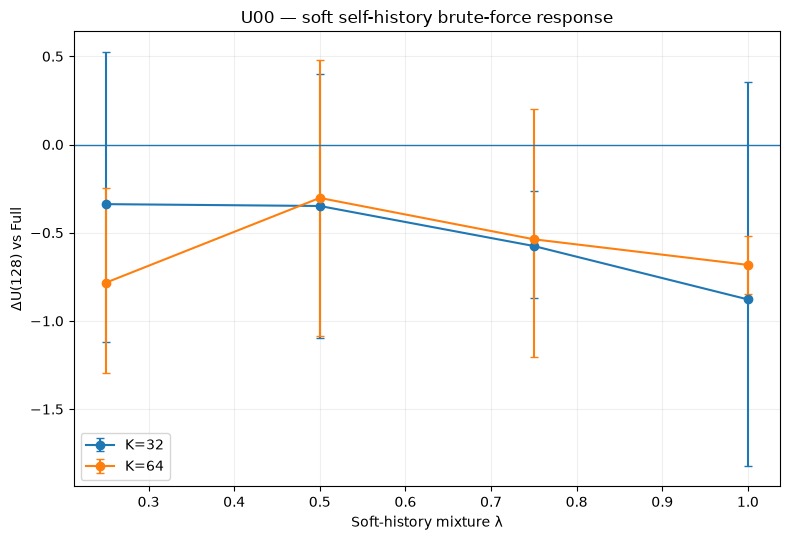

,,policy,HARD32,HARD64,S32_025,S32_050,S32_075,S64_025,S64_050,S64_075
source_id,case_id,domain,,,,,,,,
ai__raid:603b6d03-c745-4378-a2db-5b0705bddd34,gate_0026,reddit,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ai__raid:7b6ca4a8-9f9f-4ede-a9ce-4d6ca52ac525,gate_0023,books,-2.079830,NaN,0.925827,-0.746137,-0.117198,-0.616353,-1.041353,0.496019
ai__raid:7ced28f5-df4d-40ba-a6f1-e7fa8fbb9640,gate_0086,wiki,-1.045839,-0.517442,-0.680179,0.216732,-0.999630,0.000000,0.196497,-0.517442
ai__raid:a77e8e92-8af5-4e1d-ab67-65bf52a8d5d7,gate_0049,recipes,-1.294207,-0.847405,-1.445656,-1.450784,-0.486353,-1.521982,-1.124292,-1.436963
ai__raid:af383c6d-11c9-4169-a2fa-58280f83ca96,gate_0001,abstracts,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ai__raid:fcc95fec-43c3-4885-86f5-8e310a8d552f,gate_0030,news,0.907347,NaN,-0.151945,0.586461,-0.698483,-0.996018,0.757867,-0.690455


In [16]:
# U response plot + per-source instability table.
z=effects[effects.metric.eq("U128_p256")].copy()
fig,ax=plt.subplots(figsize=(8,5.5))
for K in [32,64]:
    q=z[z.K.eq(K)].sort_values("lambda")
    ax.errorbar(q["lambda"],q["mean_delta"],
                yerr=np.vstack([q.mean_delta-q.ci_low,q.ci_high-q.mean_delta]),
                marker="o",capsize=3,label=f"K={K}")
ax.axhline(0,linewidth=1);ax.grid(alpha=.2);ax.legend()
ax.set(xlabel="Soft-history mixture λ",ylabel="ΔU(128) vs Full",
       title="U00 — soft self-history brute-force response")
fig.tight_layout()
for folder in [OUT,FIG]:
    fig.savefig(folder/"U00_soft_history_U128_response.png",dpi=300,bbox_inches="tight")
    fig.savefig(folder/"U00_soft_history_U128_response.pdf",bbox_inches="tight")
plt.show()

wide=scores.pivot(index=["source_id","case_id","domain"],columns="policy",values="U128_p256")
delta=wide.subtract(wide["FULL"],axis=0).drop(columns="FULL")
display(delta)
delta.reset_index().to_csv(OUT/"U128_p256_per_source_deltas.csv",index=False)


## Blind manual review

U00 does **not** automatically score quality. The cell below writes a randomized review sheet with policy identity removed. The mapping is stored separately in `blind_key.csv`.

Suggested labels if useful: `clean`, `noticeable`, `lobotomized`, `unusable`.


In [19]:
# Blind manual review — Original AI vs the two promising soft-U policies, side by side.
import html
from IPython.display import display,HTML

REVIEW_POLICIES=["S64_025","S32_075"]

# Recover original RAID AI text used by the fixed54 pipeline.
BASE=ROOT/"results/causal/C02d2_fz118_ghostbuster_raid"
corpus=pd.read_parquet(BASE/"paired_corpus.parquet")
orig_map=corpus.set_index("source_id").text.to_dict()

rev=(
    generations[generations.policy.isin(REVIEW_POLICIES)]
    .merge(pilot[["source_id","case_id","domain","prompt"]],on=["source_id","case_id","domain"],how="left")
    .copy()
)
rev["original_ai"]=rev.source_id.map(orig_map)
assert rev.original_ai.notna().all()

rng=np.random.default_rng(SEED+99)
key=[]

for case_id,g in rev.groupby("case_id",sort=True):
    g=g.iloc[rng.permutation(len(g))].reset_index(drop=True)
    assert len(g)==2

    a,b=g.iloc[0],g.iloc[1]
    key += [
        {"case_id":case_id,"candidate":"A","policy":a.policy,"K":a.K,"lambda":a["lambda"]},
        {"case_id":case_id,"candidate":"B","policy":b.policy,"K":b.K,"lambda":b["lambda"]}
    ]

    block=f"""
    <div style="border:1px solid #aaa;border-radius:8px;padding:14px;margin:18px 0;">
      <h3>{html.escape(str(case_id))} — {html.escape(str(a.domain))}</h3>

      <div style="background:#f5f5f5;padding:10px;margin-bottom:14px;white-space:pre-wrap;">
        <b>PROMPT</b><br>{html.escape(str(a.prompt))}
      </div>

      <div style="display:grid;grid-template-columns:1fr 1fr 1fr;gap:14px;">
        <div style="border:1px solid #ccc;padding:10px;white-space:pre-wrap;">
          <b>ORIGINAL AI</b><br><br>{html.escape(str(a.original_ai))}
        </div>

        <div style="border:1px solid #ccc;padding:10px;white-space:pre-wrap;">
          <b>CANDIDATE A</b><br><br>{html.escape(str(a.generated_text))}
        </div>

        <div style="border:1px solid #ccc;padding:10px;white-space:pre-wrap;">
          <b>CANDIDATE B</b><br><br>{html.escape(str(b.generated_text))}
        </div>
      </div>
    </div>
    """
    display(HTML(block))

blind_key=pd.DataFrame(key)
blind_key.to_csv(OUT/"blind_review_key_softU.csv",index=False)

print("Policy identities remain hidden.")
print("Key saved to:",OUT/"blind_review_key_softU.csv")

Policy identities remain hidden.
Key saved to: ../results/causal/U00_soft_history_bruteforce/blind_review_key_softU.csv


## U01 gate

U00 is exploratory calibration. We want a stable region, not maximum suppression.

A promising policy should show:

1. consistently negative paired \(\Delta U(128)\);
2. a meaningful fraction of Hard32's effect;
3. the same direction under canonical \(U(256)\) when eligible;
4. no pathological result explained only by an extreme collapse of \(L_8\);
5. acceptable blind manual prose quality.

Once a region is identified, **U01** should rerun only the best 1–2 soft policies plus Full and Hard32 on a fresh, larger subset before any return to C05.


In [21]:
# Diagnose S64_025 termination failures.
diag=generations[generations.policy.eq("S64_025")].copy()
diag["hit_limit"]=diag.stop_reason.eq("max_tokens")

display(
    diag[[
        "case_id","domain","generator_tokens","stop_reason",
        "first_override_step","override_fraction","hit_limit"
    ]]
    .sort_values(["hit_limit","case_id"],ascending=[False,True])
)

bad=diag[diag.hit_limit].copy()
print(f"\nS64_025 max-token failures: {len(bad)}/{len(diag)}")

for r in bad.itertuples(index=False):
    print("\n"+"="*110)
    print(f"{r.case_id} | {r.domain} | tokens={r.generator_tokens}")
    print("\nPROMPT:")
    print(pilot.loc[pilot.source_id.eq(r.source_id),"prompt"].iloc[0])
    print("\nLAST 1500 CHARS:")
    print(r.generated_text[-1500:])

,case_id,domain,generator_tokens,stop_reason,first_override_step,override_fraction,hit_limit
23,gate_0030,news,480,max_tokens,72.0,0.031250,True
50,gate_0086,wiki,480,max_tokens,NaN,0.000000,True
5,gate_0001,abstracts,172,eos,163.0,0.005780,False
14,gate_0023,books,353,eos,101.0,0.033898,False
41,gate_0026,reddit,12,eos,NaN,0.000000,False
32,gate_0049,recipes,340,eos,137.0,0.014663,False



S64_025 max-token failures: 2/6

gate_0030 | news | tokens=480

PROMPT:
Write the body of a BBC news article titled "SA return to Mauritius". Do not repeat the title.

LAST 1500 CHARS:
auritian team. The series is expected to showcase the best of both teams and will be a highlight of the cricket calendar.

The visit of the South African cricket team to Mauritius is also expected to boost tourism in the country. The island nation is known for its beautiful beaches, lush greenery, and rich cultural heritage, and the cricket match is expected to attract more tourists to the island.

The South African cricket team's visit to Mauritius is also expected to boost the Mauritian economy. The country has been working towards diversifying its economy and the cricket match is expected to attract more foreign investment.

The South African cricket team's visit to Mauritius is also expected to boost the Mauritian economy. The country has been working towards diversifying its economy and the cricket

In [22]:
# Compare FULL vs S64_025 on the two max-token cases.
for case_id in ["gate_0030","gate_0086"]:
    z=generations[generations.case_id.eq(case_id)].set_index("policy")

    full=z.loc["FULL"]
    soft=z.loc["S64_025"]

    print("\n"+"="*110)
    print(case_id,soft.domain)
    print("FULL stop:",full.stop_reason,"tokens:",full.generator_tokens)
    print("SOFT stop:",soft.stop_reason,"tokens:",soft.generator_tokens)
    print("identical text:",full.generated_text==soft.generated_text)
    print("first override:",soft.first_override_step)
    print("override fraction:",soft.override_fraction)

    print("\nFULL tail:")
    print(full.generated_text[-1000:])
    print("\nS64_025 tail:")
    print(soft.generated_text[-1000:])


gate_0030 news
FULL stop: eos tokens: 336
SOFT stop: max_tokens tokens: 480
identical text: False
first override: 72.0
override fraction: 0.03125

FULL tail:
ic and economic ties. The cricket match is seen as a symbolic gesture to mark the progress made in bilateral relations.

Mauritian Prime Minister Pravind Jugnauth expressed his delight at the return visit, stating, "This is a significant moment for our country. It is a testament to the strong relationship we have built over the years."

The cricket match is not just a sporting event but also a cultural exchange, with both teams expected to engage in friendly interactions and cultural exchanges during the visit.

The event is expected to attract a large number of tourists to Mauritius, boosting the country's tourism industry. The cricket match is also expected to contribute to the country's economy, with hotels, restaurants, and other related businesses likely to benefit from the influx of visitors.

The return visit of the South 

In [23]:
# U01 — fine K=64 soft-history sweep on 10 cases.
# Reuses the original 6 U00 cases + 4 fresh cases; no Ghostbuster/Unique/NFZ.
U01_OUT=ROOT/"results/causal/U01_K64_lambda_fine10";U01_OUT.mkdir(parents=True,exist_ok=True)
U01_LAMBDAS=[0.10,0.15,0.175,0.20,0.225,0.25]
U01_POLICIES={lam:f"K64_L{str(lam).replace('.','')}" for lam in U01_LAMBDAS}

# Freeze 10-source cohort: original 6 + fresh review/news/abstract/book cases.
COHORT_PATH=U01_OUT/"cohort10.csv"
if COHORT_PATH.exists():
    cohort10=pd.read_csv(COHORT_PATH,keep_default_na=False)
else:
    cohort10=pilot.copy()
    rng=np.random.default_rng(SEED+101)
    extras=[]
    for domain in ["reviews","news","abstracts","books"]:
        g=prompts54[
            prompts54.domain.eq(domain)&~prompts54.source_id.isin(cohort10.source_id)
        ].sort_values("source_id").reset_index(drop=True)
        assert len(g),domain
        extras.append(g.iloc[int(rng.integers(0,len(g)))])
    cohort10=pd.concat([cohort10,pd.DataFrame(extras)],ignore_index=True)
    assert len(cohort10)==10 and cohort10.source_id.nunique()==10
    cohort10.to_csv(COHORT_PATH,index=False)

print("U01 cohort:")
display(cohort10[["case_id","source_id","domain"]])

# Seed with reusable U00 outputs: FULL + S64_025 for the original six.
GEN_PATH=U01_OUT/"generations.parquet"
if GEN_PATH.exists():
    u01gen=pd.read_parquet(GEN_PATH)
else:
    reuse=generations[
        generations.source_id.isin(cohort10.source_id)&
        generations.policy.isin(["FULL","S64_025"])
    ].copy()
    reuse["policy"]=reuse.policy.replace({"S64_025":U01_POLICIES[0.25]})
    u01gen=reuse
    u01gen.to_parquet(GEN_PATH,index=False)

# Free scorer, reload generator.
if "smodel" in globals():
    del smodel
    gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()

gmodel=AutoModelForCausalLM.from_pretrained(
    GENERATOR,dtype=dtype,low_cpu_mem_usage=True
).to(device).eval()

required=["FULL"]+[U01_POLICIES[x] for x in U01_LAMBDAS]
done=set(zip(u01gen.source_id.astype(str),u01gen.policy.astype(str)))
rows=u01gen.to_dict("records")
total=len(cohort10)*len(required)
pbar=tqdm(total=total,initial=len(done),desc="U01 generations")

for src in cohort10.itertuples(index=False):
    # Full baseline.
    key=(str(src.source_id),"FULL")
    if key not in done:
        ids,stop=generate_full(src.prompt)
        text=gtok.decode(ids,skip_special_tokens=True)
        rows.append({
            "case_id":src.case_id,"source_id":str(src.source_id),"domain":src.domain,
            "policy":"FULL","K":np.nan,"lambda":0.0,"generated_text":text,
            "generator_tokens":len(ids),"stop_reason":stop,
            "first_override_step":np.nan,"override_fraction":0.0,
            "text_sha":hashlib.sha256(text.encode()).hexdigest()
        })
        u01gen=pd.DataFrame(rows);u01gen.to_parquet(GEN_PATH,index=False);pbar.update(1)

    # Fine K64 λ sweep.
    for lam in U01_LAMBDAS:
        policy=U01_POLICIES[lam]
        key=(str(src.source_id),policy)
        if key in done:continue
        ids,stop,first,frac=generate_soft(src.prompt,64,lam)
        text=gtok.decode(ids,skip_special_tokens=True)
        rows.append({
            "case_id":src.case_id,"source_id":str(src.source_id),"domain":src.domain,
            "policy":policy,"K":64,"lambda":lam,"generated_text":text,
            "generator_tokens":len(ids),"stop_reason":stop,
            "first_override_step":first,"override_fraction":frac,
            "text_sha":hashlib.sha256(text.encode()).hexdigest()
        })
        u01gen=pd.DataFrame(rows);u01gen.to_parquet(GEN_PATH,index=False);pbar.update(1)

pbar.close()
assert len(u01gen)==10*len(required),(len(u01gen),10*len(required))

print("\nGeneration behavior:")
display(
    u01gen.groupby(["policy","lambda"]).agg(
        n=("source_id","size"),
        mean_tokens=("generator_tokens","mean"),
        eos_rate=("stop_reason",lambda x:(x=="eos").mean()),
        mean_override=("override_fraction","mean")
    ).reset_index().sort_values("lambda")
)

# Reload frozen U scorer.
del gmodel
gc.collect()
if torch.cuda.is_available():torch.cuda.empty_cache()
if "stok" not in globals():stok=AutoTokenizer.from_pretrained(SCORER,use_fast=True)
smodel=AutoModelForCausalLM.from_pretrained(
    SCORER,dtype=dtype,low_cpu_mem_usage=True
).to(device).eval()



U01 cohort:


,case_id,source_id,domain
0,gate_0001,ai__raid:af383c6d-11c9-4169-a2fa-58280f83ca96,abstracts
1,gate_0023,ai__raid:7b6ca4a8-9f9f-4ede-a9ce-4d6ca52ac525,books
2,gate_0030,ai__raid:fcc95fec-43c3-4885-86f5-8e310a8d552f,news
3,gate_0049,ai__raid:a77e8e92-8af5-4e1d-ab67-65bf52a8d5d7,recipes
4,gate_0026,ai__raid:603b6d03-c745-4378-a2db-5b0705bddd34,reddit
5,gate_0086,ai__raid:7ced28f5-df4d-40ba-a6f1-e7fa8fbb9640,wiki
6,gate_0020,ai__raid:eb76307e-f969-4523-9943-52da0e3f78a8,reviews
7,gate_0066,ai__raid:a40984f5-f447-464b-8a6a-eaa8d6f76d12,news
8,gate_0022,ai__raid:4c4676d5-c143-448c-b058-9c360b04d900,abstracts
9,gate_0047,ai__raid:70764dd8-197a-415b-8c5f-2ebd022e0fd7,books


U01 generations: 100%|██████████████████████████████████████████████████████████████████████████████████| 70/70 [11:52<00:00, 12.29s/it]


Generation behavior:


,policy,lambda,n,mean_tokens,eos_rate,mean_override
0,FULL,0.000,10,286.0,0.9,0.000000
1,K64_L01,0.100,10,296.4,0.8,0.005857
2,K64_L015,0.150,10,288.6,0.9,0.010259
3,K64_L0175,0.175,10,283.9,0.9,0.012737
4,K64_L02,0.200,10,277.5,0.9,0.017337
5,K64_L0225,0.225,10,281.8,0.9,0.020163
6,K64_L025,0.250,10,295.2,0.8,0.022202


U01 U128:   0%|                                                                                                  | 0/70 [00:00<?, ?it/s]


KeyError: 'lambda'

In [24]:
# Score primary p256 U(128). Use iterrows() so the "lambda" column keeps its name.
SCORE_PATH=U01_OUT/"U128_p256_scores.parquet"
score_rows=[]

for _,r in tqdm(u01gen.iterrows(),total=len(u01gen),desc="U01 U128"):
    s=score_protocol(r["generated_text"],256,[8,32,128])

    score_rows.append({
        "case_id":r["case_id"],
        "source_id":r["source_id"],
        "domain":r["domain"],
        "policy":r["policy"],
        "lambda":r["lambda"],
        "generator_tokens":r["generator_tokens"],
        "stop_reason":r["stop_reason"],
        "first_override_step":r["first_override_step"],
        "override_fraction":r["override_fraction"],
        "eligible":s["eligible"],
        "L8":s.get("L8",np.nan),
        "L32":s.get("L32",np.nan),
        "L128":s.get("L128",np.nan),
        "U32":s.get("U32",np.nan),
        "U128":s.get("U128",np.nan)
    })

u01score=pd.DataFrame(score_rows)
u01score.to_parquet(SCORE_PATH,index=False)

print("Saved:",SCORE_PATH)
display(
    u01score.groupby(["policy","lambda"]).agg(
        n=("source_id","size"),
        eligible=("eligible","sum")
    ).reset_index().sort_values("lambda")
)

U01 U128: 100%|█████████████████████████████████████████████████████████████████████████████████████████| 70/70 [00:04<00:00, 14.08it/s]

Saved: ../results/causal/U01_K64_lambda_fine10/U128_p256_scores.parquet


,policy,lambda,n,eligible
0,FULL,0.000,10,7
1,K64_L01,0.100,10,6
2,K64_L015,0.150,10,6
3,K64_L0175,0.175,10,6
4,K64_L02,0.200,10,6
5,K64_L0225,0.225,10,6
6,K64_L025,0.250,10,6


U01 ΔU128:


,lambda,n,mean_delta_U128,ci_low,ci_high,negative_n,negative_fraction,L025_effect_retained
0,0.100,6,0.300127,-0.159768,0.690549,1,0.166667,-15.449701
1,0.150,6,0.247191,-0.291892,0.902901,3,0.500000,-12.724717
2,0.175,6,0.045250,-0.699570,0.820912,3,0.500000,-2.329370
3,0.200,6,-0.163943,-0.920779,0.785119,4,0.666667,8.439320
4,0.225,6,0.085122,-0.738387,0.957322,2,0.333333,-4.381854
5,0.250,6,-0.019426,-0.926994,1.032698,3,0.500000,1.000000



Per-case ΔU128:


,case_id,domain,K64_L01,K64_L015,K64_L0175,K64_L02,K64_L0225,K64_L025
source_id,,,,,,,,
ai__raid:af383c6d-11c9-4169-a2fa-58280f83ca96,gate_0001,abstracts,NaN,NaN,NaN,NaN,NaN,NaN
ai__raid:7b6ca4a8-9f9f-4ede-a9ce-4d6ca52ac525,gate_0023,books,0.710971,-0.162588,-0.162588,-0.385383,0.052350,-0.616353
ai__raid:fcc95fec-43c3-4885-86f5-8e310a8d552f,gate_0030,news,0.967147,0.805195,0.443740,-0.883515,-0.537276,-0.996018
ai__raid:a77e8e92-8af5-4e1d-ab67-65bf52a8d5d7,gate_0049,recipes,-0.664414,-0.664414,-1.514603,-1.514603,-1.521930,-1.521982
ai__raid:603b6d03-c745-4378-a2db-5b0705bddd34,gate_0026,reddit,NaN,NaN,NaN,NaN,NaN,NaN
ai__raid:7ced28f5-df4d-40ba-a6f1-e7fa8fbb9640,gate_0086,wiki,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
ai__raid:eb76307e-f969-4523-9943-52da0e3f78a8,gate_0020,reviews,NaN,NaN,NaN,NaN,NaN,NaN
ai__raid:a40984f5-f447-464b-8a6a-eaa8d6f76d12,gate_0066,news,0.463395,-0.097349,-0.097349,-0.097349,0.620395,0.620395
ai__raid:4c4676d5-c143-448c-b058-9c360b04d900,gate_0022,abstracts,NaN,NaN,NaN,NaN,NaN,NaN



Gate-specific temporal diagnostics:


,case_id,policy,lambda,generator_tokens,stop_reason,first_override_step,override_fraction,U128
4,gate_0030,FULL,0.000,336,eos,NaN,0.000000,1.615801
22,gate_0030,K64_L01,0.100,360,eos,72.0,0.013850,2.582948
23,gate_0030,K64_L015,0.150,354,eos,72.0,0.028169,2.420996
24,gate_0030,K64_L0175,0.175,355,eos,72.0,0.025281,2.059541
25,gate_0030,K64_L02,0.200,324,eos,72.0,0.018462,0.732287
26,gate_0030,K64_L0225,0.225,326,eos,72.0,0.024465,1.078525
5,gate_0030,K64_L025,0.250,480,max_tokens,72.0,0.031250,0.619784
10,gate_0086,FULL,0.000,480,max_tokens,NaN,0.000000,2.234020
37,gate_0086,K64_L01,0.100,480,max_tokens,NaN,0.000000,2.234020
38,gate_0086,K64_L015,0.150,480,max_tokens,NaN,0.000000,2.234020


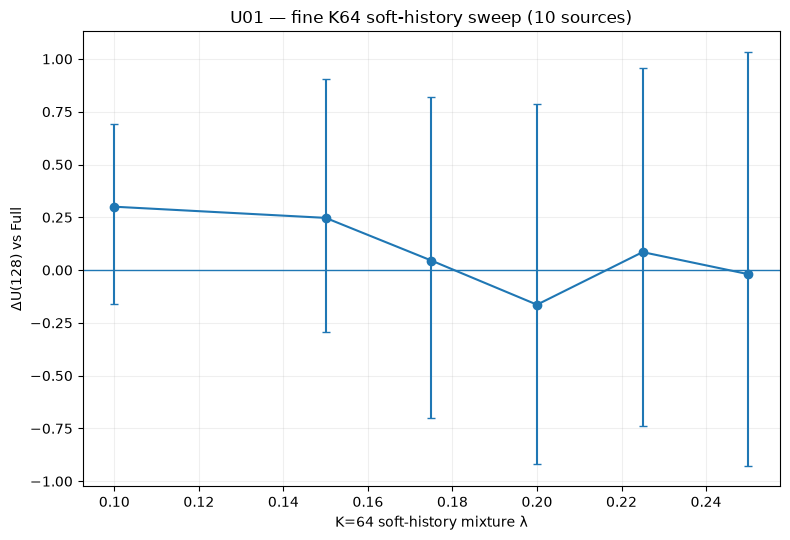

In [28]:
def u01_boot(x,seed):
    x=np.asarray(x,float);x=x[np.isfinite(x)]
    if not len(x):return np.nan,np.nan,np.nan
    rng=np.random.default_rng(seed)
    b=x[rng.integers(0,len(x),size=(5000,len(x)))].mean(1)
    return x.mean(),np.quantile(b,.025),np.quantile(b,.975)
    
# U01 paired ΔU128 summary + fraction of λ=.25 effect retained.
w=u01score.pivot(index="source_id",columns="policy",values="U128")
summary=[]
ref_policy=U01_POLICIES[0.25]

for lam in U01_LAMBDAS:
    policy=U01_POLICIES[lam]

    z=w[[policy,"FULL"]].dropna()
    d=(z[policy]-z["FULL"]).to_numpy(float)
    m,lo,hi=u01_boot(d,SEED+int(lam*10000))

    if policy==ref_policy:
        recovery=1.0 if len(d) and abs(d.mean())>1e-12 else np.nan
    else:
        common=w[[policy,"FULL",ref_policy]].dropna()
        if len(common):
            dp=(common[policy]-common["FULL"]).mean()
            dr=(common[ref_policy]-common["FULL"]).mean()
            recovery=float(dp/dr) if abs(dr)>1e-12 else np.nan
        else:
            recovery=np.nan

    summary.append({
        "lambda":lam,
        "n":len(d),
        "mean_delta_U128":m,
        "ci_low":lo,
        "ci_high":hi,
        "negative_n":int((d<0).sum()),
        "negative_fraction":float((d<0).mean()) if len(d) else np.nan,
        "L025_effect_retained":recovery
    })

u01summary=pd.DataFrame(summary)
u01summary.to_csv(U01_OUT/"lambda_summary.csv",index=False)

print("U01 ΔU128:")
display(u01summary)

# Per-case paired deltas.
delta=w.subtract(w["FULL"],axis=0).drop(columns="FULL")
meta=cohort10.set_index("source_id")[["case_id","domain"]]
delta=meta.join(delta)

print("\nPer-case ΔU128:")
display(delta)
delta.reset_index().to_csv(U01_OUT/"per_case_delta_U128.csv",index=False)

# gate_0030 / gate_0086 diagnostics.
print("\nGate-specific temporal diagnostics:")
display(
    u01score[
        u01score.case_id.isin(["gate_0030","gate_0086"])
    ][[
        "case_id","policy","lambda","generator_tokens","stop_reason",
        "first_override_step","override_fraction","U128"
    ]].sort_values(["case_id","lambda"])
)

# Response plot.
fig,ax=plt.subplots(figsize=(8,5.5))
ax.errorbar(
    u01summary["lambda"],
    u01summary["mean_delta_U128"],
    yerr=np.vstack([
        u01summary.mean_delta_U128-u01summary.ci_low,
        u01summary.ci_high-u01summary.mean_delta_U128
    ]),
    marker="o",capsize=3
)
ax.axhline(0,linewidth=1)
ax.set(
    xlabel="K=64 soft-history mixture λ",
    ylabel="ΔU(128) vs Full",
    title="U01 — fine K64 soft-history sweep (10 sources)"
)
ax.grid(alpha=.2)
fig.tight_layout()

for folder in [U01_OUT,FIG]:
    fig.savefig(folder/"U01_K64_lambda_sweep.png",dpi=300,bbox_inches="tight")
    fig.savefig(folder/"U01_K64_lambda_sweep.pdf",bbox_inches="tight")

plt.show()

U02 generations: 100%|██████████████████████████████████████████████████████████████████████████████████| 60/60 [05:40<00:00,  6.80s/it]

Generation behavior:


,n,mean_tokens,eos_rate,mean_pulses,mean_overrides,mean_override_per_pulse
policy,,,,,,
FULL,10,286.0,0.9,0.0,0.0,0.000000
PULSE8,10,271.2,1.0,27.0,5.2,0.176001
PULSE16,10,310.1,0.9,16.1,3.0,0.155243
PULSE32,10,289.1,0.8,7.5,1.3,0.156679
PULSE64,10,288.7,0.9,4.2,0.6,0.112857
HARD64,10,279.7,0.8,NaN,NaN,NaN


U02 U128: 100%|█████████████████████████████████████████████████████████████████████████████████████████| 60/60 [00:04<00:00, 14.55it/s]


U02 sparse-pulse summary:


,policy,n,mean_delta_U128,ci_low,ci_high,negative_n,negative_fraction,eos_rate,mean_tokens,mean_override_per_pulse
0,PULSE8,7,-0.177927,-1.063070,0.643326,4,0.571429,1.0,271.2,0.176001
1,PULSE16,6,-0.082558,-0.796002,0.704328,3,0.500000,0.9,310.1,0.155243
2,PULSE32,6,0.274661,0.023456,0.577816,0,0.000000,0.8,289.1,0.156679
3,PULSE64,6,-0.045183,-0.135548,0.000000,1,0.166667,0.9,288.7,0.112857
4,HARD64,5,-0.361766,-1.095574,0.365469,3,0.600000,0.8,279.7,NaN



Per-case ΔU128:


,case_id,domain,HARD64,PULSE16,PULSE32,PULSE64,PULSE8
source_id,,,,,,,
ai__raid:af383c6d-11c9-4169-a2fa-58280f83ca96,gate_0001,abstracts,NaN,NaN,NaN,NaN,NaN
ai__raid:7b6ca4a8-9f9f-4ede-a9ce-4d6ca52ac525,gate_0023,books,NaN,0.000000,0.000000,0.000000,-0.083179
ai__raid:fcc95fec-43c3-4885-86f5-8e310a8d552f,gate_0030,news,NaN,-0.385409,0.597765,0.000000,0.953202
ai__raid:a77e8e92-8af5-4e1d-ab67-65bf52a8d5d7,gate_0049,recipes,-0.847405,-1.536947,0.000000,0.000000,-2.080560
ai__raid:603b6d03-c745-4378-a2db-5b0705bddd34,gate_0026,reddit,NaN,NaN,NaN,NaN,NaN
ai__raid:7ced28f5-df4d-40ba-a6f1-e7fa8fbb9640,gate_0086,wiki,-0.517442,0.000000,0.000000,0.000000,-0.357952
ai__raid:eb76307e-f969-4523-9943-52da0e3f78a8,gate_0020,reviews,0.953730,NaN,NaN,NaN,0.505155
ai__raid:a40984f5-f447-464b-8a6a-eaa8d6f76d12,gate_0066,news,-1.616377,-0.165174,0.140737,-0.271095,-1.534809
ai__raid:4c4676d5-c143-448c-b058-9c360b04d900,gate_0022,abstracts,NaN,NaN,NaN,NaN,NaN



Previously unstable cases:


,case_id,policy,pulse_spacing,generator_tokens,stop_reason,first_override_step,pulse_count,override_count,override_fraction,U128
2,gate_0030,FULL,NaN,336,eos,NaN,0.0,0.0,0.000000,1.615801
24,gate_0030,HARD64,1.0,231,eos,NaN,NaN,NaN,NaN,NaN
20,gate_0030,PULSE8,8.0,348,eos,72.0,36.0,8.0,0.222222,2.569003
21,gate_0030,PULSE16,16.0,418,eos,96.0,23.0,9.0,0.391304,1.230392
22,gate_0030,PULSE32,32.0,480,max_tokens,96.0,13.0,3.0,0.230769,2.213566
23,gate_0030,PULSE64,64.0,336,eos,NaN,5.0,0.0,0.000000,1.615801
9,gate_0047,FULL,NaN,355,eos,NaN,0.0,0.0,0.000000,1.190934
59,gate_0047,HARD64,1.0,377,eos,NaN,NaN,NaN,NaN,1.409597
55,gate_0047,PULSE8,8.0,327,eos,80.0,33.0,6.0,0.181818,2.543589
56,gate_0047,PULSE16,16.0,363,eos,80.0,19.0,6.0,0.315789,2.783118


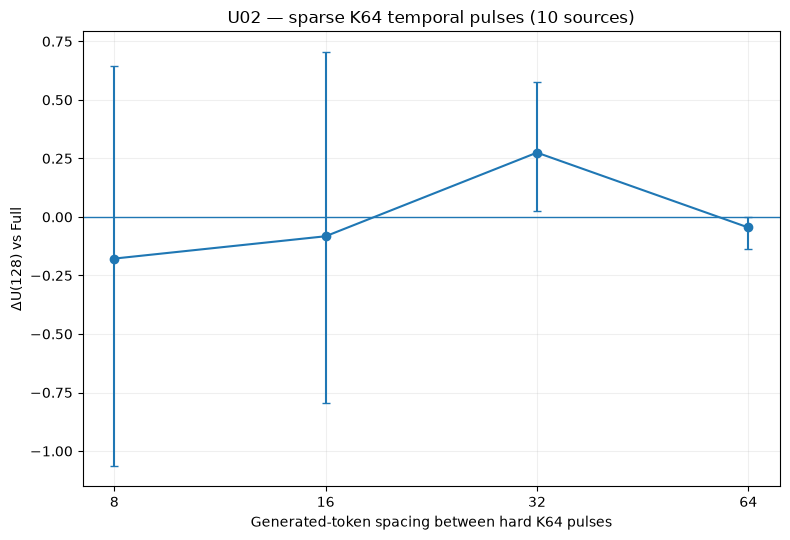

In [29]:
# U02 — sparse temporal pulses at K=64 on the same 10-source cohort.
# At pulse positions use hard K64; everywhere else use full history.
U02_OUT=ROOT/"results/causal/U02_K64_sparse_pulses10";U02_OUT.mkdir(parents=True,exist_ok=True)
PULSE_SPACINGS=[8,16,32,64]
U02_POLICIES=["FULL"]+[f"PULSE{d}" for d in PULSE_SPACINGS]+["HARD64"]

@torch.inference_mode()
def generate_pulse(prompt,K=64,spacing=16):
    p0=make_prompt_ids(prompt);p=p0[0].tolist()
    out=gmodel(input_ids=p0,use_cache=True)
    full_logits=out.logits[:,-1,:].float();past=out.past_key_values
    gen=[];pulse_count=0;override_count=0;first_override=None

    for step in range(MAX_NEW_TOKENS):
        full_choice=int(full_logits.argmax(-1).item())

        # First possible intervention is exactly when >K generated history exists.
        is_pulse=step>=K and (step-K)%spacing==0
        if is_pulse:
            pulse_count+=1
            cap=torch.tensor([p+gen[-K:]],device=device)
            cap_logits=gmodel(input_ids=cap,use_cache=False).logits[:,-1,:].float()
            nxt=int(cap_logits.argmax(-1).item())

            if nxt!=full_choice:
                override_count+=1
                if first_override is None:first_override=step
        else:
            nxt=full_choice

        if nxt in EOS:
            return gen,"eos",first_override,pulse_count,override_count

        gen.append(nxt)
        out=gmodel(
            input_ids=torch.tensor([[nxt]],device=device),
            past_key_values=past,use_cache=True
        )
        full_logits=out.logits[:,-1,:].float();past=out.past_key_values

    return gen,"max_tokens",first_override,pulse_count,override_count


# ---------------------------------------------------------------------
# GENERATION
# ---------------------------------------------------------------------
if "smodel" in globals():
    del smodel
    gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()

gmodel=AutoModelForCausalLM.from_pretrained(
    GENERATOR,dtype=dtype,low_cpu_mem_usage=True
).to(device).eval()

GEN_PATH=U02_OUT/"generations.parquet"

if GEN_PATH.exists():
    u02gen=pd.read_parquet(GEN_PATH)
else:
    # Reuse Full generations from U01 exactly.
    u02gen=u01gen[u01gen.policy.eq("FULL")].copy()
    u02gen["pulse_spacing"]=np.nan
    u02gen["pulse_count"]=0
    u02gen["override_count"]=0
    u02gen.to_parquet(GEN_PATH,index=False)

done=set(zip(u02gen.source_id.astype(str),u02gen.policy.astype(str)))
rows=u02gen.to_dict("records")
total=len(cohort10)*len(U02_POLICIES)

pbar=tqdm(total=total,initial=len(done),desc="U02 generations")

for src in cohort10.itertuples(index=False):
    # Sparse pulse policies.
    for spacing in PULSE_SPACINGS:
        policy=f"PULSE{spacing}"
        key=(str(src.source_id),policy)
        if key in done:continue

        ids,stop,first,npulse,nover=generate_pulse(src.prompt,K=64,spacing=spacing)
        text=gtok.decode(ids,skip_special_tokens=True)

        rows.append({
            "case_id":src.case_id,"source_id":str(src.source_id),"domain":src.domain,
            "policy":policy,"K":64,"lambda":np.nan,"pulse_spacing":spacing,
            "generated_text":text,"generator_tokens":len(ids),"stop_reason":stop,
            "first_override_step":first,
            "pulse_count":npulse,"override_count":nover,
            "override_fraction":nover/max(1,npulse),
            "text_sha":hashlib.sha256(text.encode()).hexdigest()
        })

        u02gen=pd.DataFrame(rows);u02gen.to_parquet(GEN_PATH,index=False);pbar.update(1)

    # Exact old hard-K64 endpoint.
    policy="HARD64";key=(str(src.source_id),policy)
    if key not in done:
        ids,stop=generate_hard(src.prompt,64)
        text=gtok.decode(ids,skip_special_tokens=True)

        rows.append({
            "case_id":src.case_id,"source_id":str(src.source_id),"domain":src.domain,
            "policy":policy,"K":64,"lambda":np.nan,"pulse_spacing":1,
            "generated_text":text,"generator_tokens":len(ids),"stop_reason":stop,
            "first_override_step":np.nan,
            "pulse_count":np.nan,"override_count":np.nan,"override_fraction":np.nan,
            "text_sha":hashlib.sha256(text.encode()).hexdigest()
        })

        u02gen=pd.DataFrame(rows);u02gen.to_parquet(GEN_PATH,index=False);pbar.update(1)

pbar.close()
assert len(u02gen)==10*len(U02_POLICIES),(len(u02gen),10*len(U02_POLICIES))

print("Generation behavior:")
display(
    u02gen.groupby("policy").agg(
        n=("source_id","size"),
        mean_tokens=("generator_tokens","mean"),
        eos_rate=("stop_reason",lambda x:(x=="eos").mean()),
        mean_pulses=("pulse_count","mean"),
        mean_overrides=("override_count","mean"),
        mean_override_per_pulse=("override_fraction","mean")
    ).reindex(U02_POLICIES)
)


# ---------------------------------------------------------------------
# U(128) SCORING
# ---------------------------------------------------------------------
del gmodel
gc.collect()
if torch.cuda.is_available():torch.cuda.empty_cache()

if "stok" not in globals():
    stok=AutoTokenizer.from_pretrained(SCORER,use_fast=True)

smodel=AutoModelForCausalLM.from_pretrained(
    SCORER,dtype=dtype,low_cpu_mem_usage=True
).to(device).eval()

SCORE_PATH=U02_OUT/"U128_p256_scores.parquet"
score_rows=[]

for _,r in tqdm(u02gen.iterrows(),total=len(u02gen),desc="U02 U128"):
    s=score_protocol(r["generated_text"],256,[8,32,128])

    score_rows.append({
        "case_id":r["case_id"],"source_id":r["source_id"],"domain":r["domain"],
        "policy":r["policy"],"pulse_spacing":r.get("pulse_spacing",np.nan),
        "generator_tokens":r["generator_tokens"],"stop_reason":r["stop_reason"],
        "first_override_step":r.get("first_override_step",np.nan),
        "pulse_count":r.get("pulse_count",np.nan),
        "override_count":r.get("override_count",np.nan),
        "override_fraction":r.get("override_fraction",np.nan),
        "eligible":s["eligible"],
        "L8":s.get("L8",np.nan),"L32":s.get("L32",np.nan),
        "L128":s.get("L128",np.nan),
        "U32":s.get("U32",np.nan),"U128":s.get("U128",np.nan)
    })

u02score=pd.DataFrame(score_rows)
u02score.to_parquet(SCORE_PATH,index=False)


# ---------------------------------------------------------------------
# PAIRED EFFECTS
# ---------------------------------------------------------------------
w=u02score.pivot(index="source_id",columns="policy",values="U128")
summary=[]

for policy in U02_POLICIES:
    if policy=="FULL":continue

    z=w[[policy,"FULL"]].dropna()
    d=(z[policy]-z["FULL"]).to_numpy(float)
    m,lo,hi=u01_boot(d,SEED+sum(map(ord,policy)))

    q=u02gen[u02gen.policy.eq(policy)]

    summary.append({
        "policy":policy,
        "n":len(d),
        "mean_delta_U128":m,
        "ci_low":lo,
        "ci_high":hi,
        "negative_n":int((d<0).sum()),
        "negative_fraction":float((d<0).mean()) if len(d) else np.nan,
        "eos_rate":float((q.stop_reason=="eos").mean()),
        "mean_tokens":float(q.generator_tokens.mean()),
        "mean_override_per_pulse":float(q.override_fraction.mean())
            if q.override_fraction.notna().any() else np.nan
    })

u02summary=pd.DataFrame(summary)
u02summary.to_csv(U02_OUT/"policy_summary.csv",index=False)

print("\nU02 sparse-pulse summary:")
display(u02summary)

delta=w.subtract(w["FULL"],axis=0).drop(columns="FULL")
meta=cohort10.set_index("source_id")[["case_id","domain"]]
delta=meta.join(delta)

print("\nPer-case ΔU128:")
display(delta)
delta.reset_index().to_csv(U02_OUT/"per_case_delta_U128.csv",index=False)


# ---------------------------------------------------------------------
# IMPORTANT CASES
# ---------------------------------------------------------------------
print("\nPreviously unstable cases:")
display(
    u02score[
        u02score.case_id.isin(["gate_0030","gate_0047","gate_0086"])
    ][[
        "case_id","policy","pulse_spacing","generator_tokens","stop_reason",
        "first_override_step","pulse_count","override_count",
        "override_fraction","U128"
    ]].sort_values(["case_id","pulse_spacing"],na_position="first")
)


# ---------------------------------------------------------------------
# RESPONSE PLOT
# ---------------------------------------------------------------------
plot=u02summary[u02summary.policy.str.startswith("PULSE")].copy()
plot["spacing"]=plot.policy.str.replace("PULSE","",regex=False).astype(int)
plot=plot.sort_values("spacing")

fig,ax=plt.subplots(figsize=(8,5.5))
ax.errorbar(
    plot["spacing"],plot["mean_delta_U128"],
    yerr=np.vstack([
        plot.mean_delta_U128-plot.ci_low,
        plot.ci_high-plot.mean_delta_U128
    ]),
    marker="o",capsize=3
)
ax.axhline(0,linewidth=1)
ax.set_xscale("log",base=2)
ax.set_xticks(PULSE_SPACINGS)
ax.set_xticklabels(PULSE_SPACINGS)
ax.set(
    xlabel="Generated-token spacing between hard K64 pulses",
    ylabel="ΔU(128) vs Full",
    title="U02 — sparse K64 temporal pulses (10 sources)"
)
ax.grid(alpha=.2);fig.tight_layout()

for folder in [U02_OUT,FIG]:
    fig.savefig(folder/"U02_sparse_K64_pulses.png",dpi=300,bbox_inches="tight")
    fig.savefig(folder/"U02_sparse_K64_pulses.pdf",bbox_inches="tight")

plt.show()

human U128: 100%|█████████████████████████████████████████████████████████████████████████████████████| 125/125 [00:10<00:00, 12.43it/s]

Same-genre validation-human U128 bands:


,domain,n,mean,std,q10,q25,median,q75,q90
0,abstracts,7,1.970349,1.543935,0.906259,1.097607,1.207071,2.288864,3.464192
1,books,14,0.854623,0.981706,-0.083840,0.287989,0.493898,1.081903,1.983833
2,news,22,1.139176,0.684958,0.360009,0.586705,1.155519,1.702752,1.985546
3,recipes,21,1.273701,0.709714,0.317121,0.753789,1.214321,1.697180,2.203318
4,reddit,4,0.705372,0.533641,0.225660,0.415201,0.678375,0.968546,1.206682
5,reviews,4,1.268175,1.364551,0.474230,0.536533,0.667588,1.399230,2.542589
6,wiki,16,1.089533,0.633735,0.349099,0.526706,1.007882,1.651000,1.918718



Per-source absolute U128 coverage:


,case_id,domain,eligible,full_U128,human_q10,human_median,human_q90,full_in_band,reachable,n_candidates,n_in_band,nearest_policy,nearest_U128,nearest_distance,in_band_policies
0,gate_0001,abstracts,False,NaN,NaN,NaN,NaN,False,False,0,0,,NaN,NaN,
1,gate_0023,books,True,2.420739,-0.083840,0.493898,1.983833,False,True,11,1,K64_L025,1.804386,0.0,K64_L025
2,gate_0030,news,True,1.615801,0.360009,1.155519,1.985546,True,True,11,6,PULSE16,1.230392,0.0,"PULSE16, K64_L0225, K64_L02, FULL, PULSE64, K6..."
3,gate_0049,recipes,True,2.781869,0.317121,1.214321,2.203318,False,True,12,9,PULSE16,1.244923,0.0,"PULSE16, K64_L025, K64_L0225, K64_L0175, K64_L..."
4,gate_0026,reddit,False,NaN,NaN,NaN,NaN,False,False,0,0,,NaN,NaN,
5,gate_0086,wiki,True,2.234020,0.349099,1.007882,1.918718,False,True,12,2,HARD64,1.716578,0.0,"HARD64, PULSE8"
6,gate_0020,reviews,True,0.143834,0.474230,0.667588,2.542589,False,True,3,2,PULSE8,0.648990,0.0,"PULSE8, HARD64"
7,gate_0066,news,True,2.444922,0.360009,1.155519,1.985546,False,True,12,2,PULSE8,0.910113,0.0,"PULSE8, HARD64"
8,gate_0022,abstracts,False,NaN,NaN,NaN,NaN,False,False,0,0,,NaN,NaN,
9,gate_0047,books,True,1.190934,-0.083840,0.493898,1.983833,True,True,12,4,FULL,1.190934,0.0,"FULL, PULSE64, HARD64, K64_L01"


...

,policy,family,U128,delta_from_full,inside_human_band,distance_to_band,generator_tokens,stop_reason
0,PULSE8,pulse,0.648990,0.505155,True,0.000000,273,eos
1,HARD64,hard,1.097565,0.953730,True,0.000000,330,eos
2,FULL,full,0.143834,0.000000,False,0.330395,268,eos



gate_0066 | news | human band [0.360, 1.986] | median 1.156


,policy,family,U128,delta_from_full,inside_human_band,distance_to_band,generator_tokens,stop_reason
0,PULSE8,pulse,0.910113,-1.534809,True,0.000000,367,eos
1,HARD64,hard,0.828546,-1.616377,True,0.000000,480,max_tokens
2,PULSE64,pulse,2.173827,-0.271095,False,0.188281,457,eos
3,PULSE16,pulse,2.279748,-0.165174,False,0.294202,463,eos
4,K64_L015,soft_mix,2.347573,-0.097349,False,0.362027,394,eos
5,K64_L0175,soft_mix,2.347573,-0.097349,False,0.362027,394,eos
6,K64_L02,soft_mix,2.347573,-0.097349,False,0.362027,394,eos
7,FULL,full,2.444922,0.000000,False,0.459376,383,eos
8,PULSE32,pulse,2.585660,0.140737,False,0.600114,347,eos
9,K64_L01,soft_mix,2.908317,0.463395,False,0.922771,480,max_tokens



gate_0047 | books | human band [-0.084, 1.984] | median 0.494


,policy,family,U128,delta_from_full,inside_human_band,distance_to_band,generator_tokens,stop_reason
0,FULL,full,1.190934,0.000000,True,0.000000,355,eos
1,PULSE64,pulse,1.190934,0.000000,True,0.000000,339,eos
2,HARD64,hard,1.409597,0.218663,True,0.000000,377,eos
3,K64_L01,soft_mix,1.514596,0.323662,True,0.000000,380,eos
4,PULSE32,pulse,2.100398,0.909464,False,0.116566,273,eos
5,PULSE8,pulse,2.543589,1.352655,False,0.559756,327,eos
6,PULSE16,pulse,2.783118,1.592184,False,0.799285,363,eos
7,K64_L015,soft_mix,2.793237,1.602303,False,0.809404,302,eos
8,K64_L0175,soft_mix,2.793237,1.602303,False,0.809404,305,eos
9,K64_L02,soft_mix,3.088128,1.897194,False,1.104295,352,eos


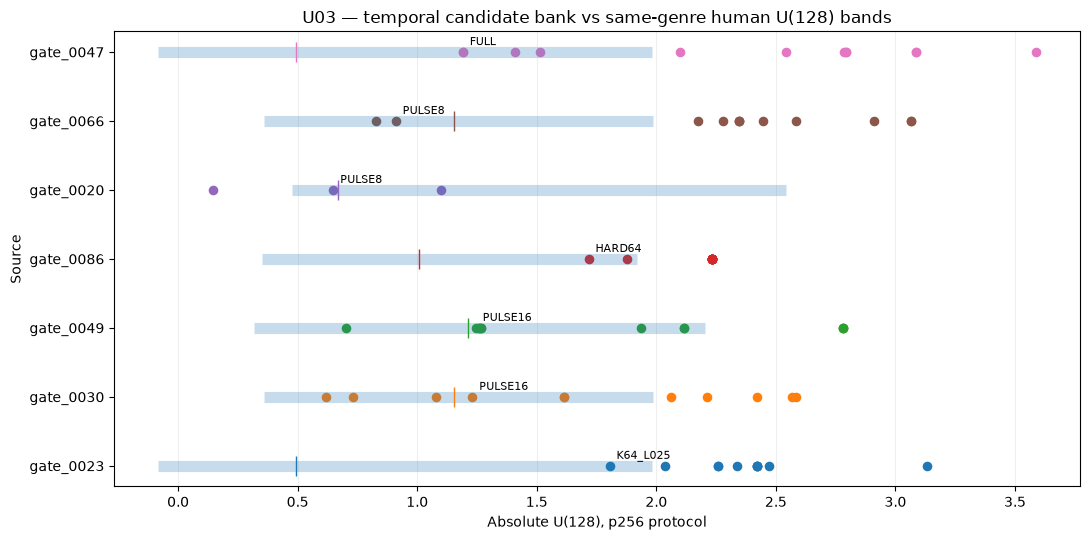

In [30]:
# U03 — absolute U(128) candidate coverage against same-genre human validation bands.
U03_OUT=ROOT/"results/causal/U03_absolute_U128_human_bands";U03_OUT.mkdir(parents=True,exist_ok=True)
HUMAN_CACHE=U03_OUT/"raid_validation_human_U128_p256.parquet"

# ---------------------------------------------------------------------
# 1. Score fixed RAID validation humans with the exact same p256 protocol.
# ---------------------------------------------------------------------
RAID_BASE=ROOT/"results/causal/C02d2_fz118_ghostbuster_raid"
meta=pd.read_parquet(RAID_BASE/"fz118_paired_features.parquet")
corpus=pd.read_parquet(RAID_BASE/"paired_corpus.parquet")

human_meta=(
    meta[
        meta.dataset.eq("raid")
        & meta.split.eq("validation")
        & meta.label.eq(0)
        & meta.domain.isin(cohort10.domain.unique())
    ][["source_id","domain"]]
    .drop_duplicates("source_id")
)
human_text=human_meta.merge(
    corpus[["source_id","text"]],
    on="source_id",how="left",validate="one_to_one"
)
assert human_text.text.notna().all()

if HUMAN_CACHE.exists():
    human_u=pd.read_parquet(HUMAN_CACHE)
else:
    # scorer should still be loaded from U02; restore only if needed.
    if "smodel" not in globals():
        if "stok" not in globals():
            stok=AutoTokenizer.from_pretrained(SCORER,use_fast=True)
        smodel=AutoModelForCausalLM.from_pretrained(
            SCORER,dtype=dtype,low_cpu_mem_usage=True
        ).to(device).eval()

    rows=[]
    for r in tqdm(human_text.itertuples(index=False),total=len(human_text),desc="human U128"):
        s=score_protocol(r.text,256,[8,32,128])
        rows.append({
            "source_id":r.source_id,"domain":r.domain,
            "eligible":s["eligible"],
            "scorer_tokens":s["scorer_tokens"],
            "L8":s.get("L8",np.nan),
            "L32":s.get("L32",np.nan),
            "L128":s.get("L128",np.nan),
            "U32":s.get("U32",np.nan),
            "U128":s.get("U128",np.nan)
        })
    human_u=pd.DataFrame(rows)
    human_u.to_parquet(HUMAN_CACHE,index=False)

human_ok=human_u[human_u.eligible & human_u.U128.notna()].copy()

# Empirical central 80% human band, by genre.
bands=(
    human_ok.groupby("domain").U128
    .agg(
        n="size",
        mean="mean",
        std="std",
        q10=lambda x:np.quantile(x,.10),
        q25=lambda x:np.quantile(x,.25),
        median="median",
        q75=lambda x:np.quantile(x,.75),
        q90=lambda x:np.quantile(x,.90)
    )
    .reset_index()
)
bands.to_csv(U03_OUT/"human_validation_U128_bands.csv",index=False)

print("Same-genre validation-human U128 bands:")
display(bands)


# ---------------------------------------------------------------------
# 2. Combine every temporal candidate already generated in U01 + U02.
# ---------------------------------------------------------------------
a=u01score[[
    "case_id","source_id","domain","policy","U128","eligible",
    "generator_tokens","stop_reason","first_override_step","override_fraction"
]].copy()
a["family"]="soft_mix"

b=u02score[[
    "case_id","source_id","domain","policy","U128","eligible",
    "generator_tokens","stop_reason","first_override_step","override_fraction"
]].copy()
b["family"]="pulse"

# FULL is duplicated across notebooks; HARD64 only needs one copy.
cand=pd.concat([a,b],ignore_index=True)
cand=cand.drop_duplicates(["source_id","policy"],keep="first")
cand=cand[cand.eligible & cand.U128.notna()].copy()

# Label endpoint families more accurately.
cand.loc[cand.policy.eq("FULL"),"family"]="full"
cand.loc[cand.policy.eq("HARD64"),"family"]="hard"

cand=cand.merge(
    bands[["domain","n","q10","median","q90"]],
    on="domain",how="left",validate="many_to_one"
)
assert cand[["q10","median","q90"]].notna().all().all()

cand["inside_human_band"]=cand.U128.between(cand.q10,cand.q90)
cand["distance_to_median"]=(cand.U128-cand["median"]).abs()
cand["distance_to_band"]=np.where(
    cand.inside_human_band,
    0.,
    np.minimum((cand.U128-cand.q10).abs(),(cand.U128-cand.q90).abs())
)

# Full baseline absolute U for each source.
full_u=(
    cand[cand.policy.eq("FULL")]
    .set_index("source_id").U128
    .to_dict()
)
cand["full_U128"]=cand.source_id.map(full_u)
cand["delta_from_full"]=cand.U128-cand.full_U128

cand.to_csv(U03_OUT/"all_temporal_candidates_absolute_U128.csv",index=False)


# ---------------------------------------------------------------------
# 3. Per-source reachability of the human band.
# ---------------------------------------------------------------------
rows=[]
for src in cohort10.itertuples(index=False):
    g=cand[cand.source_id.eq(src.source_id)].copy()

    if not len(g):
        rows.append({
            "case_id":src.case_id,"domain":src.domain,
            "eligible":False,"full_U128":np.nan,
            "human_q10":np.nan,"human_median":np.nan,"human_q90":np.nan,
            "full_in_band":False,"reachable":False,
            "n_candidates":0,"n_in_band":0,
            "nearest_policy":"","nearest_U128":np.nan,
            "nearest_distance":np.nan,"in_band_policies":""
        })
        continue

    g=g.sort_values(["distance_to_band","distance_to_median"])
    best=g.iloc[0]
    inside=g[g.inside_human_band].sort_values("distance_to_median")
    full=g[g.policy.eq("FULL")]

    rows.append({
        "case_id":src.case_id,
        "domain":src.domain,
        "eligible":True,
        "full_U128":float(full.U128.iloc[0]) if len(full) else np.nan,
        "human_q10":float(g.q10.iloc[0]),
        "human_median":float(g["median"].iloc[0]),
        "human_q90":float(g.q90.iloc[0]),
        "full_in_band":bool(full.inside_human_band.iloc[0]) if len(full) else False,
        "reachable":bool(len(inside)),
        "n_candidates":len(g),
        "n_in_band":len(inside),
        "nearest_policy":best.policy,
        "nearest_U128":float(best.U128),
        "nearest_distance":float(best.distance_to_band),
        "in_band_policies":", ".join(inside.policy.astype(str))
    })

coverage=pd.DataFrame(rows)
coverage.to_csv(U03_OUT/"source_human_band_coverage.csv",index=False)

print("\nPer-source absolute U128 coverage:")
display(coverage)

eligible=coverage[coverage.eligible]
print(
    f"\nEligible sources: {len(eligible)}/{len(coverage)}\n"
    f"Full already in human band: {eligible.full_in_band.sum()}/{len(eligible)} "
    f"({eligible.full_in_band.mean():.1%})\n"
    f"Reachable with existing temporal bank: {eligible.reachable.sum()}/{len(eligible)} "
    f"({eligible.reachable.mean():.1%})"
)


# ---------------------------------------------------------------------
# 4. Show every candidate around the human band.
# ---------------------------------------------------------------------
for case_id in coverage.loc[coverage.eligible,"case_id"]:
    z=cand[cand.case_id.eq(case_id)].sort_values(
        ["inside_human_band","distance_to_band","distance_to_median"],
        ascending=[False,True,True]
    )

    print("\n"+"="*110)
    print(
        f"{case_id} | {z.domain.iloc[0]} | "
        f"human band [{z.q10.iloc[0]:.3f}, {z.q90.iloc[0]:.3f}] | "
        f"median {z['median'].iloc[0]:.3f}"
    )

    display(
        z[[
            "policy","family","U128","delta_from_full",
            "inside_human_band","distance_to_band",
            "generator_tokens","stop_reason"
        ]].reset_index(drop=True)
    )


# ---------------------------------------------------------------------
# 5. Absolute-U visualization.
# ---------------------------------------------------------------------
plot_cases=coverage.loc[coverage.eligible,"case_id"].tolist()
fig,ax=plt.subplots(figsize=(11,max(5.5,.65*len(plot_cases))))

for yi,case_id in enumerate(plot_cases):
    z=cand[cand.case_id.eq(case_id)]
    lo=z.q10.iloc[0];med=z["median"].iloc[0];hi=z.q90.iloc[0]

    # Human q10-q90 interval + median.
    ax.hlines(yi,lo,hi,linewidth=8,alpha=.25)
    ax.plot(med,yi,"|",markersize=14)

    # All generated temporal candidates.
    ax.scatter(z.U128,np.full(len(z),yi),s=35)

    # Label closest candidate.
    best=z.sort_values(["distance_to_band","distance_to_median"]).iloc[0]
    ax.annotate(
        best.policy,(best.U128,yi),
        xytext=(5,5),textcoords="offset points",fontsize=8
    )

ax.set_yticks(range(len(plot_cases)))
ax.set_yticklabels(plot_cases)
ax.set_xlabel("Absolute U(128), p256 protocol")
ax.set_ylabel("Source")
ax.set_title("U03 — temporal candidate bank vs same-genre human U(128) bands")
ax.grid(axis="x",alpha=.2)
fig.tight_layout()

for folder in [U03_OUT,FIG]:
    fig.savefig(folder/"U03_absolute_U128_human_bands.png",dpi=300,bbox_inches="tight")
    fig.savefig(folder/"U03_absolute_U128_human_bands.pdf",bbox_inches="tight")

plt.show()

In [31]:
# End-of-session checkpoint — everything so far belongs to U00.
from pathlib import Path
import json,pandas as pd

CHECK=ROOT/"results/causal/U00_soft_history_bruteforce"
CHECK.mkdir(parents=True,exist_ok=True)

# Remove misleading checkpoint filenames from the earlier version, if created.
for old in [
    "u01_generations_checkpoint.parquet","u01_scores_checkpoint.parquet",
    "u01_summary_checkpoint.parquet","u02_generations_checkpoint.parquet",
    "u02_scores_checkpoint.parquet","u02_summary_checkpoint.parquet",
    "u03_human_bands_checkpoint.parquet","u03_candidates_checkpoint.parquet",
    "u03_coverage_checkpoint.parquet"
]:
    p=CHECK/old
    if p.exists():p.unlink()

# Save all U00 subexperiment state.
tables={
    "u00_coarse_generations":globals().get("generations"),
    "u00_coarse_scores":globals().get("scores"),
    "u00_coarse_effects":globals().get("effects"),

    # Fine K64 lambda sweep — still U00.
    "u00_fine_k64_generations":globals().get("u01gen"),
    "u00_fine_k64_scores":globals().get("u01score"),
    "u00_fine_k64_summary":globals().get("u01summary"),

    # Sparse-pulse sweep — still U00.
    "u00_sparse_pulse_generations":globals().get("u02gen"),
    "u00_sparse_pulse_scores":globals().get("u02score"),
    "u00_sparse_pulse_summary":globals().get("u02summary"),

    # Absolute-U / human-band audit — still U00.
    "u00_human_U128_bands":globals().get("bands"),
    "u00_temporal_candidate_bank":globals().get("cand"),
    "u00_absolute_U_coverage":globals().get("coverage"),
}

saved=[]
for name,df in tables.items():
    if isinstance(df,pd.DataFrame):
        path=CHECK/f"{name}_checkpoint.parquet"
        df.to_parquet(path,index=False)
        saved.append((name,len(df),str(path)))

state={
    "date":"2026-09-15",
    "current_notebook":"U00",
    "next_notebook":"U01",
    "generator":"Qwen/Qwen2.5-1.5B-Instruct",
    "u_scorer":"Qwen/Qwen3-0.6B-Base",
    "primary_tuning_measure":"U128 p256",
    "canonical_long_measure":"U256 p384 where eligible",

    "U00":{
        "scope":"All U-series work performed so far.",
        "subexperiments":{
            "coarse_soft_history":{
                "cohort_n":6,
                "policies":"K32/K64 arithmetic probability mixing at lambda .25/.50/.75 plus hard endpoints",
                "finding":"S64_025 was blind-preferred in every meaningfully comparable case and strongly moved U, but occasional trajectory degeneration remained."
            },
            "fine_K64_lambda":{
                "cohort_n":10,
                "policies":["K64_L01","K64_L015","K64_L0175","K64_L02","K64_L0225","K64_L025"],
                "finding":"Continuous soft mixing is strongly source/trajectory dependent; no universal lambda gives stable directional U movement."
            },
            "sparse_K64_pulses":{
                "cohort_n":10,
                "policies":["PULSE8","PULSE16","PULSE32","PULSE64","HARD64"],
                "finding":"Sparse pulses improve some generation stability but U direction remains source dependent."
            },
            "absolute_U_audit":{
                "finding":"On the current pilot, the existing temporal candidate bank reached the same-genre validation-human U128 band for all 7/7 eligible sources. Exact band matching is secondary to content preservation."
            }
        }
    },

    "main_conclusion":"A single universal temporal policy is unstable because autoregressive trajectories respond discontinuously. A fixed bank of temporal generation policies provides useful diversity in U while allowing quality-based candidate filtering.",

    "selection_principle":"Content/coherence preservation is the primary constraint. AI text is population-level higher in U, so global downward pressure is a net benefit; occasional overshoot past the human band is much less concerning than lobotomization.",

    "planned_U01":[
        "Print outputs from the viable U00 temporal interventions.",
        "Manually select the 5 least-lobotomizing methods.",
        "Run those 5 methods on a substantially larger cohort.",
        "Evaluate robustness of content preservation and U reduction.",
        "Keep the 3 most robust temporal methods.",
        "Final pipeline later generates those 3 candidates in parallel, with Unique control also active.",
        "Reject lobotomized/bad candidates.",
        "Among the remaining good candidates, select the one with the lowest locally computed U.",
        "Then apply the remainder of the NFZ suffix."
    ],

    "important_note":"Do not use Ghostbuster scores to choose U interventions. C05 is paused until the U intervention is frozen."
}

(CHECK/"U_SERIES_SESSION_STATE.json").write_text(json.dumps(state,indent=2))

handoff="""# U-series handoff — end of U00

## Naming
Everything performed so far belongs to **U00**.

There is currently no U01/U02/U03 notebook.

The experiments informally referred to during development as U01/U02/U03 were only subexperiments/cells inside U00:
- U00 coarse soft-history sweep
- U00 fine K64 lambda sweep
- U00 sparse K64 pulse sweep
- U00 absolute-U / human-band audit

The next actual notebook will be **U01**.

## Objective
Develop a generation-side temporal intervention that suppresses the elevated context-utility trace U while preserving semantic/content quality.

Generator:
Qwen/Qwen2.5-1.5B-Instruct

Frozen U scorer:
Qwen/Qwen3-0.6B-Base

Primary tuning measurement:
U(128), p256 protocol

Canonical long-context confirmation:
U(256), p384 protocol where eligible

## What U00 established

### Coarse soft-history sweep
Arithmetic mixing between full generated history and capped generated history was tested.

S64_025 (K=64, lambda=.25) was substantially more coherent than the competing strong K32 setting in blind review while retaining a strong U effect.

However, some autoregressive trajectories still degenerated or failed to terminate.

### Fine K64 lambda sweep
K=64 was swept over lambda:
0.10, 0.15, 0.175, 0.20, 0.225, 0.25.

There was no stable global lambda.
The sign and magnitude of completed-text U movement were strongly source-dependent because small next-token perturbations caused divergent autoregressive trajectories.

### Sparse-pulse sweep
Hard K64 temporal suppression was applied only at deterministic intervals:
8, 16, 32, 64 tokens.

Sparse pulsing improved some generation behavior but did not eliminate source-dependent U instability.

### Absolute-U audit
The candidate bank from the soft and pulse sweeps was compared against same-genre validation-human U(128) bands.

Among the 7/10 pilot sources eligible for the p256 U(128) measurement:
- only 2/7 Full generations were already in-band;
- at least one existing temporal candidate was in-band for 7/7.

This showed that a small temporal-policy bank gives strong practical U reachability even though no single policy is universally directional.

## Current interpretation
Do not search for one universal temporal knob.

The temporal intervention is generation-side and causal, but autoregressive branching makes each policy's completed-text U response source-dependent.

The practical solution is therefore a small fixed bank of robust temporal generation methods.

## U01 plan
1. Print outputs from the viable U00 intervention methods.
2. Manually choose the 5 least-lobotomizing methods.
3. Test those 5 on a substantially larger cohort.
4. Keep the 3 most robust methods.
5. Final temporal controller:
   - generate 3 candidates in parallel;
   - eventually apply Unique control during those generations;
   - reject lobotomized/bad candidates;
   - among surviving candidates choose the one with the lowest locally computed U;
   - send the selected text through the rest of the NFZ suffix.

This makes the procedure statistic-quasi-deterministic:
temporal generation creates the candidate set, a quality gate preserves content, and frozen local U selects among valid candidates.

## C05 / Ghostbuster
Paused until the U intervention is frozen.

Ghostbuster must not be used to choose or tune the U intervention.
It remains a downstream evaluation.
"""

(CHECK/"U_SERIES_HANDOFF.md").write_text(handoff)

print("U00 checkpoint complete.")
for name,n,path in saved:
    print(f"  {name}: {n} rows -> {path}")
print(" ",CHECK/"U_SERIES_SESSION_STATE.json")
print(" ",CHECK/"U_SERIES_HANDOFF.md")
print("\nNext actual notebook: U01")

U00 checkpoint complete.
  u00_coarse_generations: 54 rows -> ../results/causal/U00_soft_history_bruteforce/u00_coarse_generations_checkpoint.parquet
  u00_coarse_scores: 54 rows -> ../results/causal/U00_soft_history_bruteforce/u00_coarse_scores_checkpoint.parquet
  u00_coarse_effects: 80 rows -> ../results/causal/U00_soft_history_bruteforce/u00_coarse_effects_checkpoint.parquet
  u00_fine_k64_generations: 70 rows -> ../results/causal/U00_soft_history_bruteforce/u00_fine_k64_generations_checkpoint.parquet
  u00_fine_k64_scores: 70 rows -> ../results/causal/U00_soft_history_bruteforce/u00_fine_k64_scores_checkpoint.parquet
  u00_fine_k64_summary: 6 rows -> ../results/causal/U00_soft_history_bruteforce/u00_fine_k64_summary_checkpoint.parquet
  u00_sparse_pulse_generations: 60 rows -> ../results/causal/U00_soft_history_bruteforce/u00_sparse_pulse_generations_checkpoint.parquet
  u00_sparse_pulse_scores: 60 rows -> ../results/causal/U00_soft_history_bruteforce/u00_sparse_pulse_scores_check